## Import bibliotek i wybór urządzenia

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cpu | urządzenie: cpu


## 1. Dane: FashionMNIST z augmentacją i bez

In [2]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
train_tf_plain = test_tf
train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_plain)
train_aug = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

def loaders(train_ds, bs=128):
    return (DataLoader(train_ds, batch_size=bs, shuffle=True),
            DataLoader(test_ds, batch_size=256, shuffle=False))

print("Trening:", len(train_plain), "| Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.47MB/s]


Trening: 60000 | Test: 10000


## 2. Model MLP z przełącznikami

In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

## 3. Funkcje treningu i ewaluacji

In [4]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

def run_training(model, train_dl, test_dl, epochs=12, lr=1e-3,
                 weight_decay=0.0, optimizer="adam", use_scheduler=False, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    n = len(train_dl.dataset)
    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item()*yb.numel()
        if sched: sched.step()
        tr = run/n
        te, acc = evaluate(model, test_dl)
        hist["train_loss"].append(tr)
        hist["test_loss"].append(te)
        hist["test_acc"].append(acc)
        if verbose:
            print(f"Epoka {epoch:2d} | trening {tr:.3f} | test {te:.3f} | accuracy {acc*100:.2f}%")
    return hist

## 4. Baseline

In [5]:
print("== BASELINE ==")
tr_dl, te_dl = loaders(train_plain)
base = MLP(use_bn=False, p_drop=0.0)
hist_base = run_training(base, tr_dl, te_dl, epochs=12, lr=1e-3, weight_decay=0.0, use_scheduler=False)

== BASELINE ==
Epoka  1 | trening 0.489 | test 0.414 | accuracy 84.79%
Epoka  2 | trening 0.351 | test 0.355 | accuracy 87.17%
Epoka  3 | trening 0.312 | test 0.356 | accuracy 87.25%
Epoka  4 | trening 0.286 | test 0.345 | accuracy 87.54%
Epoka  5 | trening 0.267 | test 0.343 | accuracy 87.52%
Epoka  6 | trening 0.253 | test 0.333 | accuracy 88.18%
Epoka  7 | trening 0.234 | test 0.320 | accuracy 88.60%
Epoka  8 | trening 0.221 | test 0.334 | accuracy 88.62%
Epoka  9 | trening 0.211 | test 0.334 | accuracy 88.28%
Epoka 10 | trening 0.200 | test 0.379 | accuracy 88.16%
Epoka 11 | trening 0.190 | test 0.357 | accuracy 88.14%
Epoka 12 | trening 0.181 | test 0.356 | accuracy 88.66%


## 5. Testowanie ulepszeń (każde osobno)

In [6]:
EPOCHS = 12
results = []

# A: Weight Decay
print("\n== A: WEIGHT DECAY ==")
tr_dl, te_dl = loaders(train_plain)
m_a = MLP(use_bn=False, p_drop=0.0)
hist_a = run_training(m_a, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, weight_decay=1e-4, verbose=False)
results.append({"name": "Weight Decay", "hist": hist_a, "config": "Adam, WD=1e-4"})

# B: Dropout
print("\n== B: DROPOUT ==")
tr_dl, te_dl = loaders(train_plain)
m_b = MLP(use_bn=False, p_drop=0.3)
hist_b = run_training(m_b, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, verbose=False)
results.append({"name": "Dropout", "hist": hist_b, "config": "p_drop=0.3"})

# C: BatchNorm
print("\n== C: BATCHNORM ==")
tr_dl, te_dl = loaders(train_plain)
m_c = MLP(use_bn=True, p_drop=0.0)
hist_c = run_training(m_c, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, verbose=False)
results.append({"name": "BatchNorm", "hist": hist_c, "config": "use_bn=True"})

# D: Scheduler
print("\n== D: SCHEDULER ==")
tr_dl, te_dl = loaders(train_plain)
m_d = MLP(use_bn=False, p_drop=0.0)
hist_d = run_training(m_d, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, use_scheduler=True, verbose=False)
results.append({"name": "Scheduler", "hist": hist_d, "config": "StepLR (gamma=0.5)"})

# E: Augmentacja
print("\n== E: AUGMENTACJA ==")
tr_dl, te_dl = loaders(train_aug)
m_e = MLP(use_bn=False, p_drop=0.0)
hist_e = run_training(m_e, tr_dl, te_dl, epochs=EPOCHS, lr=1e-3, verbose=False)
results.append({"name": "Augmentacja", "hist": hist_e, "config": "RandomCrop + Flip"})


== A: WEIGHT DECAY ==

== B: DROPOUT ==

== C: BATCHNORM ==

== D: SCHEDULER ==

== E: AUGMENTACJA ==


## 6. Tabela wyników

In [7]:
print("\n" + "="*80)
print(f"{'Wariant':<15} | {'Test Acc':<10} | {'Przerwa (Test-Train)':<20} | Konfiguracja")
print("="*80)

best_acc = 0.0
best_result = None

# Baseline
gap_base = hist_base["test_loss"][-1] - hist_base["train_loss"][-1]
acc_base = hist_base["test_acc"][-1]
print(f"{'Baseline':<15} | {acc_base*100:>6.2f}%   | {gap_base:>+10.4f}             | Brak regularyzacji")

# Ulepszenia
for r in results:
    gap = r["hist"]["test_loss"][-1] - r["hist"]["train_loss"][-1]
    acc = r["hist"]["test_acc"][-1]
    print(f"{r['name']:<15} | {acc*100:>6.2f}%   | {gap:>+10.4f}             | {r['config']}")

    if acc > best_acc:
        best_acc = acc
        best_result = r

print("="*80)
print(f"\n🏆 Najlepszy wariant: {best_result['name']} (Test Acc: {best_acc*100:.2f}%)")


Wariant         | Test Acc   | Przerwa (Test-Train) | Konfiguracja
Baseline        |  88.66%   |    +0.1752             | Brak regularyzacji
Weight Decay    |  88.26%   |    +0.1529             | Adam, WD=1e-4
Dropout         |  88.32%   |    +0.0592             | p_drop=0.3
BatchNorm       |  89.42%   |    +0.1730             | use_bn=True
Scheduler       |  89.29%   |    +0.1566             | StepLR (gamma=0.5)
Augmentacja     |  84.43%   |    -0.0304             | RandomCrop + Flip

🏆 Najlepszy wariant: BatchNorm (Test Acc: 89.42%)


## 7. Krzywe uczenia - Baseline vs Najlepszy

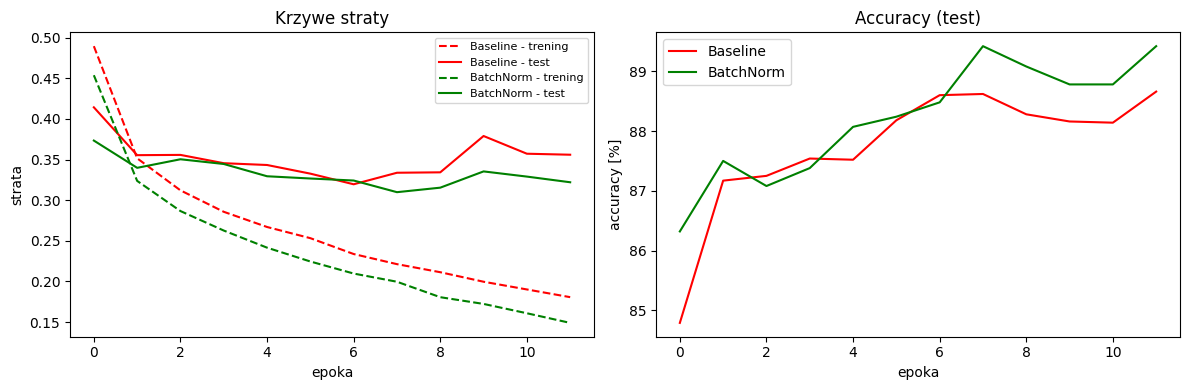


Przerwa train-test:
  Baseline: +0.1752
  BatchNorm: +0.1730

Wniosek: Zmniejszono przerwę train-test, co oznacza mniej przeuczenia.


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Baseline
ax1.plot(hist_base["train_loss"], "--", color="red", label="Baseline - trening")
ax1.plot(hist_base["test_loss"], "-", color="red", label="Baseline - test")
ax2.plot([a*100 for a in hist_base["test_acc"]], color="red", label="Baseline")

# Najlepszy
ax1.plot(best_result["hist"]["train_loss"], "--", color="green", label=f"{best_result['name']} - trening")
ax1.plot(best_result["hist"]["test_loss"], "-", color="green", label=f"{best_result['name']} - test")
ax2.plot([a*100 for a in best_result["hist"]["test_acc"]], color="green", label=best_result['name'])

ax1.set_xlabel("epoka")
ax1.set_ylabel("strata")
ax1.legend(fontsize=8)
ax1.set_title("Krzywe straty")

ax2.set_xlabel("epoka")
ax2.set_ylabel("accuracy [%]")
ax2.legend()
ax2.set_title("Accuracy (test)")

plt.tight_layout()
plt.show()

# Komentarz do przerwy
gap_base = hist_base["test_loss"][-1] - hist_base["train_loss"][-1]
gap_best = best_result["hist"]["test_loss"][-1] - best_result["hist"]["train_loss"][-1]
print(f"\nPrzerwa train-test:")
print(f"  Baseline: {gap_base:+.4f}")
print(f"  {best_result['name']}: {gap_best:+.4f}")
print(f"\nWniosek: {'Zmniejszono' if gap_best < gap_base else 'Nie zmniejszono'} przerwę train-test, co oznacza {'mniej' if gap_best < gap_base else 'tyle samo'} przeuczenia.")